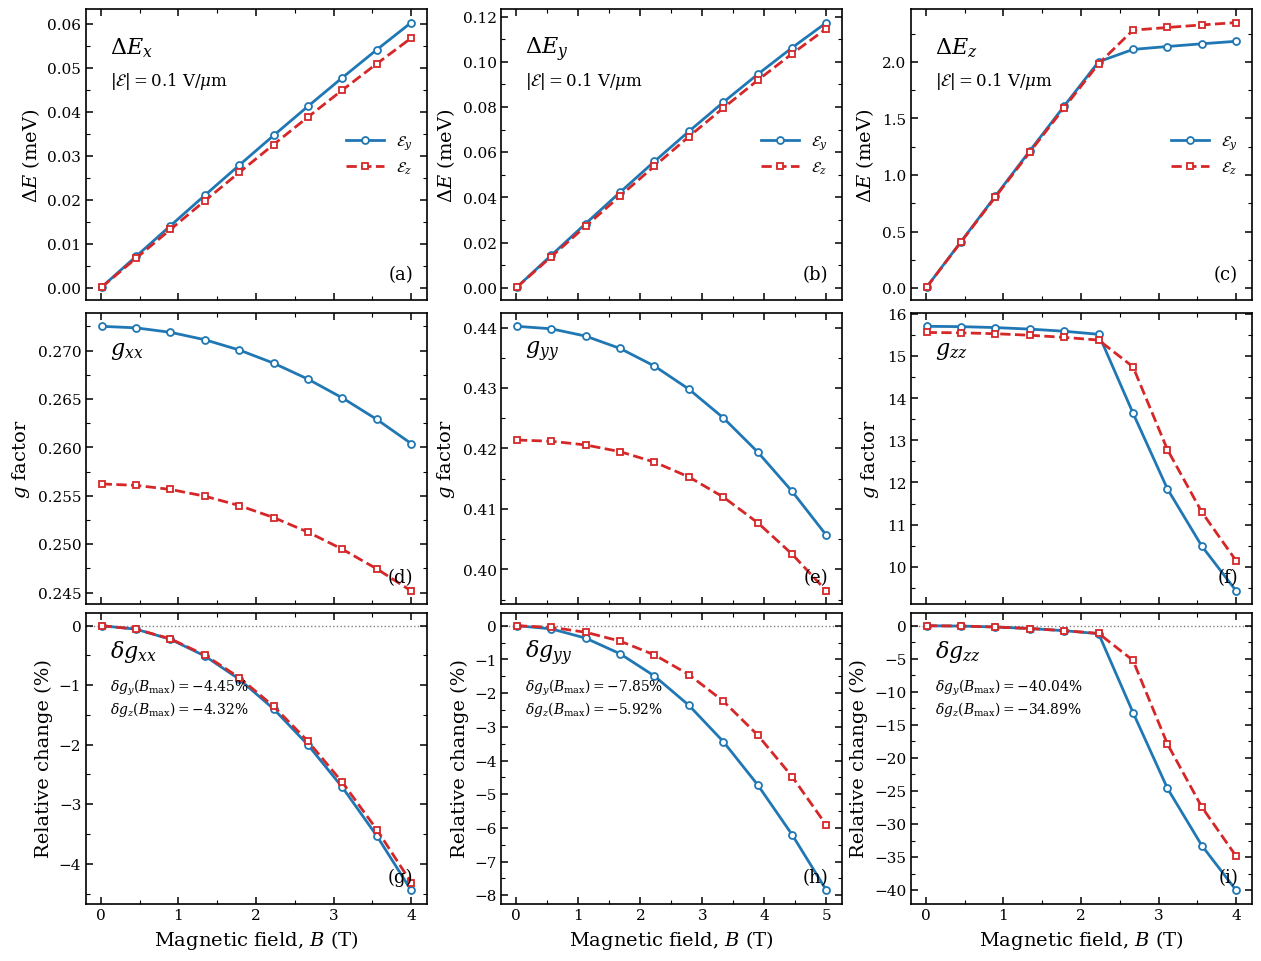

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# --------------------------------------------------
# Plot settings
# --------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 1.2,
})

N = 50
L = 300
E = 0.1

# --------------------------------------------------
# Load data
#
# Columns:
# 0 = size (nm)
# 1 = electric field (V/um)
# 2 = magnetic field B (T)
# 3 = splitting (eV)
# 4 = g factor
# --------------------------------------------------

gxx_ey_data = np.loadtxt(f"gfactor_xx_vs_Ey_N{N}_L{L}.dat")
gxx_ez_data = np.loadtxt(f"gfactor_xx_vs_Ez_N{N}_L{L}.dat")

gyy_ey_data = np.loadtxt(f"gfactor_yy_vs_Ey_N{N}_L{L}.dat")
gyy_ez_data = np.loadtxt(f"gfactor_yy_vs_Ez_N{N}_L{L}.dat")

gzz_ey_data = np.loadtxt(f"gfactor_zz_vs_Ey_N{N}_L{L}.dat")
gzz_ez_data = np.loadtxt(f"gfactor_zz_vs_Ez_N{N}_L{L}.dat")

datasets = [
    (
        gxx_ey_data,
        gxx_ez_data,
        r"$\Delta E_x$",
        r"$g_{xx}$",
        r"$\delta g_{xx}$",
    ),
    (
        gyy_ey_data,
        gyy_ez_data,
        r"$\Delta E_y$",
        r"$g_{yy}$",
        r"$\delta g_{yy}$",
    ),
    (
        gzz_ey_data,
        gzz_ez_data,
        r"$\Delta E_z$",
        r"$g_{zz}$",
        r"$\delta g_{zz}$",
    ),
]

electric_field_label = (
    rf"$|\mathcal{{E}}|={E:g}\ \mathrm{{V}}/\mu\mathrm{{m}}$"
)

# --------------------------------------------------
# Helper functions
# --------------------------------------------------

def prepare_data(data):
    """Ensure two-dimensional data sorted by magnetic field."""
    data = np.atleast_2d(data)
    return data[np.argsort(data[:, 2])]


def relative_g_change(data):
    """
    Calculate 100 * [g(B) - g(0)] / g(0).

    The first finite g value at the smallest |B| is used as g(0).
    This is useful because g = DeltaE/(mu_B B) is undefined exactly
    at B = 0.
    """
    finite = np.isfinite(data[:, 4])

    if not np.any(finite):
        raise ValueError("No finite g-factor values were found.")

    finite_indices = np.where(finite)[0]
    reference_index = finite_indices[
        np.argmin(np.abs(data[finite_indices, 2]))
    ]

    g0 = data[reference_index, 4]
    relative_change = 100.0 * (data[:, 4] - g0) / g0

    return relative_change, g0, data[reference_index, 2]


# --------------------------------------------------
# Create 3 × 3 figure
# --------------------------------------------------

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12.5, 9.5),
    sharex="col",
    constrained_layout=True,
)

for col, (
    ey_data,
    ez_data,
    splitting_label,
    g_label,
    relative_label,
) in enumerate(datasets):

    ey_data = prepare_data(ey_data)
    ez_data = prepare_data(ez_data)

    B_ey = ey_data[:, 2]
    B_ez = ez_data[:, 2]

    delta_E_ey = ey_data[:, 3] * 1000.0  # eV -> meV
    delta_E_ez = ez_data[:, 3] * 1000.0

    g_ey = ey_data[:, 4]
    g_ez = ez_data[:, 4]

    relative_ey, g0_ey, B0_ey = relative_g_change(ey_data)
    relative_ez, g0_ez, B0_ez = relative_g_change(ez_data)

    # Axes for the current column
    ax_splitting = axes[0, col]
    ax_g = axes[1, col]
    ax_relative = axes[2, col]

    # ==================================================
    # First row: energy splitting
    # ==================================================

    ax_splitting.plot(
        B_ey,
        delta_E_ey,
        color="#1f77b4",
        linestyle="-",
        marker="o",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
        label=r"$\mathcal{E}_y$",
    )

    ax_splitting.plot(
        B_ez,
        delta_E_ez,
        color="#d62728",
        linestyle="--",
        marker="s",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
        label=r"$\mathcal{E}_z$",
    )

    ax_splitting.set_ylabel(r"$\Delta E$ (meV)")

    ax_splitting.text(
        0.07,
        0.91,
        splitting_label,
        transform=ax_splitting.transAxes,
        fontsize=16,
        va="top",
        ha="left",
    )

    ax_splitting.text(
        0.07,
        0.79,
        electric_field_label,
        transform=ax_splitting.transAxes,
        fontsize=12,
        va="top",
        ha="left",
    )

    ax_splitting.legend(
        loc="best",
        frameon=False,
        handlelength=2.5,
    )

    # ==================================================
    # Second row: g factor
    # ==================================================

    ax_g.plot(
        B_ey,
        g_ey,
        color="#1f77b4",
        linestyle="-",
        marker="o",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
    )

    ax_g.plot(
        B_ez,
        g_ez,
        color="#d62728",
        linestyle="--",
        marker="s",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
    )

    ax_g.set_ylabel(r"$g$ factor")

    ax_g.text(
        0.07,
        0.91,
        g_label,
        transform=ax_g.transAxes,
        fontsize=16,
        va="top",
        ha="left",
    )

    # ==================================================
    # Third row: relative change in g factor
    # ==================================================

    ax_relative.plot(
        B_ey,
        relative_ey,
        color="#1f77b4",
        linestyle="-",
        marker="o",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
    )

    ax_relative.plot(
        B_ez,
        relative_ez,
        color="#d62728",
        linestyle="--",
        marker="s",
        markersize=5,
        linewidth=2.0,
        markerfacecolor="white",
        markeredgewidth=1.3,
    )

    ax_relative.axhline(
        0.0,
        color="0.5",
        linestyle=":",
        linewidth=1.0,
        zorder=0,
    )

    ax_relative.set_xlabel(r"Magnetic field, $B$ (T)")
    ax_relative.set_ylabel(r"Relative change (%)")

    ax_relative.text(
        0.07,
        0.91,
        relative_label,
        transform=ax_relative.transAxes,
        fontsize=16,
        va="top",
        ha="left",
    )

    # Annotate the change at maximum B
    final_text = (
        rf"$\delta g_y(B_{{\max}})={relative_ey[-1]:.2f}\%$"
        "\n"
        rf"$\delta g_z(B_{{\max}})={relative_ez[-1]:.2f}\%$"
    )

    ax_relative.text(
        0.07,
        0.78,
        final_text,
        transform=ax_relative.transAxes,
        fontsize=10,
        va="top",
        ha="left",
    )

    # --------------------------------------------------
    # Tick formatting
    # --------------------------------------------------

    for ax in (ax_splitting, ax_g, ax_relative):
        ax.tick_params(
            which="major",
            direction="in",
            length=5,
            width=1.1,
            top=True,
            right=True,
        )

        ax.tick_params(
            which="minor",
            direction="in",
            length=3,
            width=0.8,
            top=True,
            right=True,
        )

        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# --------------------------------------------------
# Panel labels
# --------------------------------------------------

panel_labels = [
    "(a)", "(b)", "(c)",
    "(d)", "(e)", "(f)",
    "(g)", "(h)", "(i)",
]

for ax, label in zip(axes.flat, panel_labels):
    ax.text(
        0.96,
        0.06,
        label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=13,
    )

# --------------------------------------------------
# Save and display
# --------------------------------------------------

plt.savefig(
    f"splitting_gfactor_relative_change_E_{E}_N{N}_L{L}.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.savefig(
    f"splitting_gfactor_relative_change_E_{E}_N{N}_L{L}.svg")

plt.savefig(
    f"splitting_gfactor_relative_change_E_{E}_N{N}_L{L}.png",
    bbox_inches="tight",
    dpi=300,
)

plt.show()